<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/av_twin_acoustic_reconstruction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# [CELL 1 - Environment Setup & Imports]
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"AV-Twin Acoustic Simulation Environment Initialized on: {device}")

AV-Twin Acoustic Simulation Environment Initialized on: cuda


In [6]:
# [CELL 2 - Surface Material & Acoustic Property Representation]

class RoomAcousticModel(nn.Module):
    """
    Represents room surfaces (walls, floor, ceiling, furniture) with trainable
    surface absorption coefficients alpha in [0, 1].
    """
    def __init__(self, num_surfaces: int = 6, room_volume: float = 50.0, total_surface_area: float = 95.0):
        super().__init__()
        self.room_volume = room_volume
        self.total_surface_area = total_surface_area

        # Initialize trainable absorption coefficients (e.g., concrete/drywall initial guess = 0.15)
        # Parameterized using sigmoid to keep alpha strictly between 0.02 (reflective) and 0.95 (absorptive)
        self.raw_alpha = nn.Parameter(torch.tensor([-1.5] * num_surfaces, device=device))

    @property
    def absorption_coefficients(self) -> torch.Tensor:
        return 0.02 + 0.93 * torch.sigmoid(self.raw_alpha)

    def forward(self) -> torch.Tensor:
        """
        Differentiable Sabine / Eyring reverberation time (RT60) estimator proxy:
        RT60 = (0.161 * V) / A_total, where A_total = sum(S_i * alpha_i)
        """
        alphas = self.absorption_coefficients
        # Assume uniform surface area distribution across surfaces for simulation proxy
        surface_areas = torch.tensor([self.total_surface_area / len(alphas)] * len(alphas), device=device)
        total_absorption = torch.sum(surface_areas * alphas)

        # Sabine reverberation time equation (seconds)
        rt60 = (0.161 * self.room_volume) / torch.clamp(total_absorption, min=0.1)
        return rt60

room_model = RoomAcousticModel().to(device)
print(f"Initial Simulated RT60: {room_model().item():.3f} seconds")

Initial Simulated RT60: 0.447 seconds


In [7]:
# [CELL 3 - Smartphone RIR Target & Acoustic Loss Function]

# Simulate a "measured" smartphone RIR target from a real-world room scan
# (e.g., target room has higher absorption from rugs/couches, yielding target RT60 = 0.42s)
target_measured_rt60 = torch.tensor([0.42], device=device)

def compute_acoustic_loss(predicted_rt60: torch.Tensor, target_rt60: torch.Tensor) -> torch.Tensor:
    """L2 loss between simulated differentiable acoustic rendering and smartphone RIR measurements."""
    return F.mse_loss(predicted_rt60, target_rt60)

print("Acoustic Loss Function Configured for Inverse Rendering.")

Acoustic Loss Function Configured for Inverse Rendering.


In [8]:
# [CELL 4 - Differentiable Optimization of Surface Materials]

optimizer = optim.Adam(room_model.parameters(), lr=0.05)
epochs = 150

history = []
print("Starting Differentiable Acoustic Optimization (Material Property Recovery)...")

for epoch in range(epochs):
    optimizer.zero_grad()

    # Forward pass: Differentiable acoustic rendering
    predicted_rt60 = room_model()
    loss = compute_acoustic_loss(predicted_rt60, target_measured_rt60)

    # Backpropagation through acoustic rendering pipeline
    loss.backward()
    optimizer.step()

    history.append((loss.item(), predicted_rt60.item()))

    if (epoch + 1) % 30 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6f} | Current RT60: {predicted_rt60.item():.3f}s")

print("Material Property Optimization Complete.")
print(f"Recovered Surface Absorption Coefficients (alpha): {room_model.absorption_coefficients.detach().cpu().numpy()}")

Starting Differentiable Acoustic Optimization (Material Property Recovery)...


/tmp/ipykernel_1402/2330678820.py:9: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(predicted_rt60, target_rt60)


Epoch 30/150 | Loss: 0.000010 | Current RT60: 0.423s
Epoch 60/150 | Loss: 0.000000 | Current RT60: 0.419s
Epoch 90/150 | Loss: 0.000000 | Current RT60: 0.420s
Epoch 120/150 | Loss: 0.000000 | Current RT60: 0.420s
Epoch 150/150 | Loss: 0.000000 | Current RT60: 0.420s
Material Property Optimization Complete.
Recovered Surface Absorption Coefficients (alpha): [0.20175551 0.20175551 0.20175551 0.20175551 0.20175551 0.20175551]


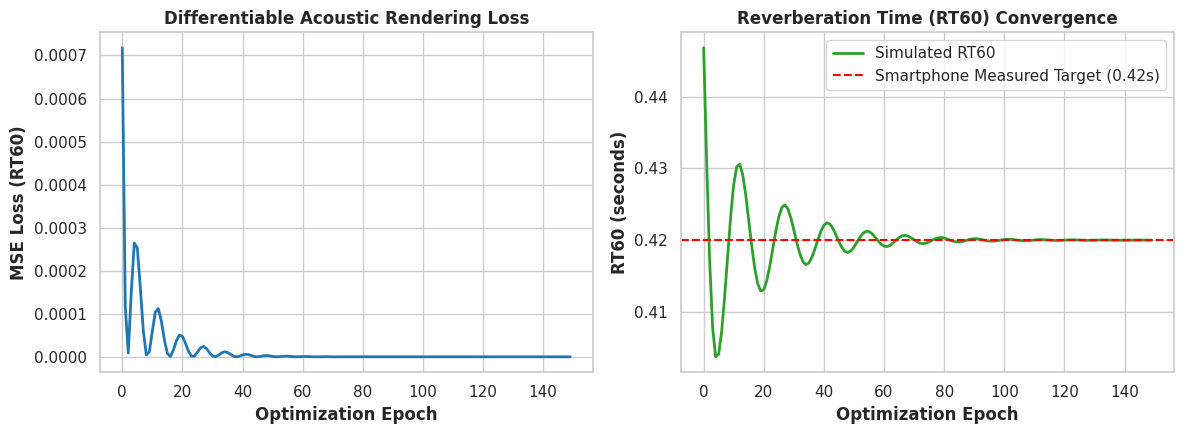

AV-Twin acoustic optimization plot saved successfully as av_twin_acoustic_optimization.png.


In [9]:
# [CELL 5 - Visualization of Optimization & Material Convergence]

losses = [h[0] for h in history]
rt60_values = [h[1] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel A: Optimization Loss Curve
axes[0].plot(losses, color='#1f77b4', lw=2)
axes[0].set_title("Differentiable Acoustic Rendering Loss", fontweight='bold')
axes[0].set_xlabel("Optimization Epoch", fontweight='bold')
axes[0].set_ylabel("MSE Loss (RT60)", fontweight='bold')

# Panel B: RT60 Convergence vs Smartphone Target
axes[1].plot(rt60_values, color='#2ca02c', lw=2, label='Simulated RT60')
axes[1].axhline(y=target_measured_rt60.item(), color='red', linestyle='--', label='Smartphone Measured Target (0.42s)')
axes[1].set_title("Reverberation Time (RT60) Convergence", fontweight='bold')
axes[1].set_xlabel("Optimization Epoch", fontweight='bold')
axes[1].set_ylabel("RT60 (seconds)", fontweight='bold')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig("av_twin_acoustic_optimization.png", dpi=300)
plt.show()

print("AV-Twin acoustic optimization plot saved successfully as av_twin_acoustic_optimization.png.")